# 03: Puan tahmini

Soru: bir filme daha önce hiç bakmadan, sadece TMDB'deki bilgilerine bakarak kaç puan vereceğimi tahmin edebilir miyim?

355 film az olduğu için dikkatli gidiyorum:
- Değerlendirmeyi 5 katlı çapraz doğrulamayı 10 kez tekrarlayarak yapıyorum (50 ayrı eğitim/test bölmesi). Tek bir bölmeye bakıp şansa güvenmek istemiyorum.
- Her modeli, herkese ortalama puanımı tahmin eden bir **temel çizgiyle** ve iki değişkenli basit bir modelle karşılaştırıyorum.
- Ön işleme (eksik doldurma, ölçekleme) her bölmenin içinde, sadece eğitim kısmından öğrenilerek yapılıyor. Böylece test bilgisi eğitime sızmıyor.
- Ana karşılaştırmada sabit, makul ayarlar kullanıyorum. Ayar seçimini ve "en iyi model" seçimini ayrıca iç içe çapraz doğrulamayla yapıyorum (bölüm 3), çünkü aynı sonuçlara bakarak hem seçip hem puanlamak skoru olduğundan iyi gösterir.
- Kalp (`liked`) ve puanlama tarihiyle ilgili sütunları kullanmıyorum, çünkü yeni bir film için bunlar zaten bilinmiyor ya da puanın kendisiyle birlikte oluşuyor.

Girdi: `data/processed/analysis_table.csv`

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, LogisticRegression
from sklearn.model_selection import (KFold, RepeatedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from statsmodels.miscmodels.ordinal_model import OrderedModel
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings('ignore', category=UserWarning)   # LightGBM/sklearn özellik adı uyarıları

ROOT = Path('..').resolve()
FIG = ROOT / 'reports' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
SEED = 42

df = pd.read_csv(ROOT / 'data' / 'processed' / 'analysis_table.csv')
GENRES = [c for c in df.columns if c.startswith('g_')]

def build(frame):
    """Bir film tablosundan model özelliklerini üretir. Hem puanladıklarım hem izleme listesi için kullanılıyor."""
    g = (frame['genres'].fillna('').str.get_dummies(sep='|').add_prefix('g_')
         .reindex(columns=GENRES, fill_value=0))
    X = pd.DataFrame({
        'year': frame['year'],
        'runtime': frame['runtime'].replace(0, np.nan),
        'tmdb_vote_average': frame['tmdb_vote_average'],
        'log_votes': np.log1p(frame['tmdb_vote_count']),
        'log_popularity': np.log1p(frame['popularity']),
        'n_genres': g.sum(axis=1),
        'is_english': (frame['original_language'] == 'en').astype(int),
        'is_turkish': (frame['original_language'] == 'tr').astype(int),
    })
    out = pd.concat([X, g], axis=1)
    out.columns = out.columns.str.replace(' ', '_')   # LightGBM boşluklu adları sevmiyor
    return out

X = build(df)
y = df['rating'].values
print(X.shape, 'özellik sayısı:', X.shape[1])
print('Eksik değer:', X.isna().sum()[X.isna().sum() > 0].to_dict())

(355, 27) özellik sayısı: 27
Eksik değer: {}


## 1. Modeller

- **Temel çizgi:** hep eğitim kümesinin ortalamasını tahmin eder.
- **Sadece TMDB puanı** ve **film yılı + TMDB puanı:** iki değişkenli basit doğrusal modeller. EDA'da en güçlü çıkan iki değişken bunlardı.
- **Ridge** ve **Lasso:** tüm özelliklerle, ceza katsayısını eğitim kümesi içinde seçiyor.
- **Spline + Ridge:** film yılı ve TMDB puanının etkisi düz bir çizgi olmak zorunda değil. Bu ikisine kübik spline uyguluyorum, diğer özellikler doğrusal kalıyor. Hâlâ yorumlanabilir bir model.
- **Sıralı lojistik regresyon:** puanlarım 0,5 ile 5 arasında sıralı bir ölçek, aslında sürekli bir sayı değil. Bu model her puan basamağının olasılığını veriyor, tahmin olarak da beklenen puanı alıyorum. 2 ve altı çok az olduğu için (30 film) onları tek basamakta birleştiriyorum. Kararlı kalsın diye dört özellik kullanıyorum: film yılı, TMDB puanı, log oy sayısı ve İngilizce olup olmaması.
- **Random Forest**, **Gradient Boosting**, **XGBoost**, **LightGBM:** doğrusal olmayan ilişkileri ve etkileşimleri yakalayabilsinler diye. Küçük veri için sığ ağaçlar ve düşük öğrenme hızıyla ayarladım.

In [2]:
class OrdinalLogit(BaseEstimator, RegressorMixin):
    """statsmodels OrderedModel'i sklearn'e uyduran küçük sarmalayıcı. Tahmin = beklenen puan."""
    def __init__(self, cols=('year', 'tmdb_vote_average', 'log_votes', 'is_english'), floor=2.0):
        self.cols = cols
        self.floor = floor

    def _z(self, X):
        Z = X[list(self.cols)].astype(float).fillna(self.mu_)
        return ((Z - self.mu_) / self.sd_).reset_index(drop=True)

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        Xs = X[list(self.cols)].astype(float)
        self.mu_, self.sd_ = Xs.mean(), Xs.std()
        yb = np.maximum(y, self.floor)                     # 2 ve altı tek basamak
        self.levels_ = np.sort(np.unique(yb))
        self.values_ = np.array([y[yb == l].mean() for l in self.levels_])
        endog = pd.Series(pd.Categorical(yb, categories=self.levels_, ordered=True))
        self.res_ = OrderedModel(endog, self._z(X), distr='logit').fit(method='bfgs', disp=False, maxiter=5000)
        return self

    def predict(self, X):
        P = np.asarray(self.res_.model.predict(self.res_.params, exog=self._z(X).values))
        return P @ self.values_

def linear_on(cols):
    ct = ColumnTransformer([('sec', 'passthrough', cols)], remainder='drop')
    return make_pipeline(ct, SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())

prep = lambda: [SimpleImputer(strategy='median'), StandardScaler()]
spline_cols = ['year', 'tmdb_vote_average']
other_cols = [c for c in X.columns if c not in spline_cols]

models = {
    'Temel çizgi (ortalama)': DummyRegressor(strategy='mean'),
    'Sadece TMDB puanı': linear_on(['tmdb_vote_average']),
    'Film yılı + TMDB puanı': linear_on(['year', 'tmdb_vote_average']),
    'Ridge (tüm özellikler)': make_pipeline(*prep(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
    'Lasso (tüm özellikler)': make_pipeline(*prep(), LassoCV(cv=5, random_state=SEED, max_iter=20000)),
    'Spline + Ridge': make_pipeline(
        ColumnTransformer([('spl', SplineTransformer(n_knots=5, degree=3), spline_cols),
                           ('rest', make_pipeline(*prep()), other_cols)]),
        RidgeCV(alphas=np.logspace(-2, 3, 30))),
    'Sıralı lojistik': OrdinalLogit(),
    'Random Forest': make_pipeline(SimpleImputer(strategy='median'),
        RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                              random_state=SEED, n_jobs=1)),
    'Gradient Boosting': make_pipeline(SimpleImputer(strategy='median'),
        GradientBoostingRegressor(n_estimators=200, learning_rate=0.03, max_depth=2,
                                  subsample=0.7, random_state=SEED)),
    'XGBoost': make_pipeline(XGBRegressor(n_estimators=300, learning_rate=0.03, max_depth=2,
                                          subsample=0.7, colsample_bytree=0.7, min_child_weight=3,
                                          random_state=SEED, n_jobs=1)),
    'LightGBM': make_pipeline(LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=4,
                                            min_child_samples=10, subsample=0.7, subsample_freq=1,
                                            colsample_bytree=0.7, random_state=SEED, n_jobs=1, verbose=-1)),
}

cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)   # tüm modeller aynı 50 bölmeyi görüyor
scoring = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}

res = {}
for name, m in models.items():
    s = cross_validate(m, X, y, cv=cv, scoring=scoring, n_jobs=1)
    res[name] = {k: -s[f'test_{k}'] if k != 'r2' else s['test_r2'] for k in scoring}
    print(f'{name:26s} RMSE {res[name]["rmse"].mean():.3f} (±{res[name]["rmse"].std():.3f})  '
          f'MAE {res[name]["mae"].mean():.3f}  R² {res[name]["r2"].mean():.3f}')

Temel çizgi (ortalama)     RMSE 0.910 (±0.070)  MAE 0.738  R² -0.014


Sadece TMDB puanı          RMSE 0.703 (±0.057)  MAE 0.553  R² 0.386


Film yılı + TMDB puanı     RMSE 0.682 (±0.054)  MAE 0.533  R² 0.423


Ridge (tüm özellikler)     RMSE 0.686 (±0.047)  MAE 0.525  R² 0.418


Lasso (tüm özellikler)     RMSE 0.671 (±0.051)  MAE 0.513  R² 0.443


Spline + Ridge             RMSE 0.685 (±0.053)  MAE 0.533  R² 0.419


Sıralı lojistik            RMSE 0.656 (±0.056)  MAE 0.509  R² 0.467


Random Forest              RMSE 0.649 (±0.054)  MAE 0.511  R² 0.479


Gradient Boosting          RMSE 0.664 (±0.056)  MAE 0.517  R² 0.453


XGBoost                    RMSE 0.665 (±0.056)  MAE 0.519  R² 0.451


LightGBM                   RMSE 0.662 (±0.058)  MAE 0.519  R² 0.456


## 2. Karşılaştırma

50 bölme birbirinden bağımsız değil (aynı filmler tekrar tekrar test kümesine giriyor), bu yüzden sıradan bir eşleşmiş t testi p değerleri fazla iyimser çıkar. Nadeau ve Bengio'nun düzeltilmiş tekrarlı örnekleme t testini kullanıyorum. Önce temel çizgiyle karşılaştırıyorum. Fark = temel çizgi RMSE'si eksi model RMSE'si, yani pozitif fark modelin daha iyi olduğunu gösterir.

                 model  RMSE  RMSE_sd   MAE     R2  RMSE_kazancı  düzeltilmiş_p
         Random Forest 0.649    0.054 0.511  0.479         0.261            0.0
       Sıralı lojistik 0.656    0.056 0.509  0.467         0.254            0.0
              LightGBM 0.662    0.058 0.519  0.456         0.248            0.0
     Gradient Boosting 0.664    0.056 0.517  0.453         0.246            0.0
               XGBoost 0.665    0.056 0.519  0.451         0.245            0.0
Lasso (tüm özellikler) 0.671    0.051 0.513  0.443         0.240            0.0
Film yılı + TMDB puanı 0.682    0.054 0.533  0.423         0.229            0.0
        Spline + Ridge 0.685    0.053 0.533  0.419         0.225            0.0
Ridge (tüm özellikler) 0.686    0.047 0.525  0.418         0.225            0.0
     Sadece TMDB puanı 0.703    0.057 0.553  0.386         0.207            0.0
Temel çizgi (ortalama) 0.910    0.070 0.738 -0.014         0.000            NaN


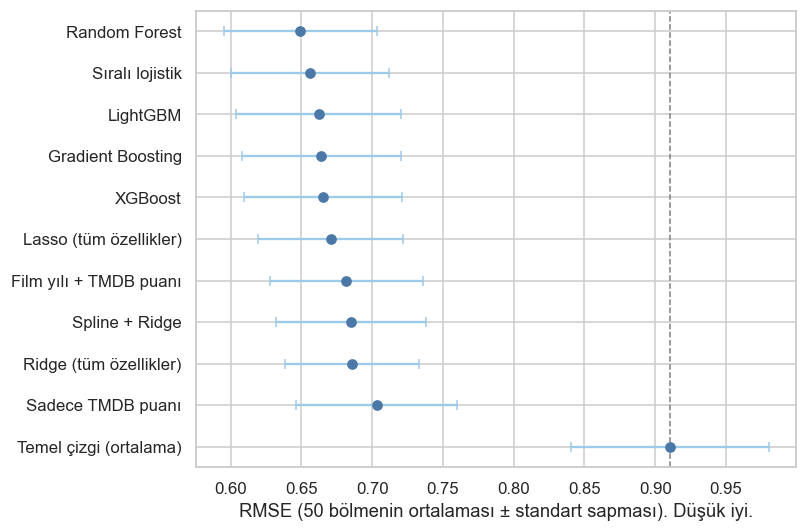

In [3]:
def corrected_t(diff, test_frac=0.2):
    # 5 katlı CV: test/eğitim oranı 0,2 / 0,8
    k = len(diff)
    var = diff.var(ddof=1)
    t = diff.mean() / np.sqrt((1 / k + test_frac / (1 - test_frac)) * var)
    return t, 2 * stats.t.sf(abs(t), k - 1)

BASE = 'Temel çizgi (ortalama)'
base = res[BASE]['rmse']
rows = []
for name, r in res.items():
    d = base - r['rmse']
    t, p = corrected_t(d) if name != BASE else (np.nan, np.nan)
    rows.append({'model': name, 'RMSE': r['rmse'].mean(), 'RMSE_sd': r['rmse'].std(),
                 'MAE': r['mae'].mean(), 'R2': r['r2'].mean(),
                 'RMSE_kazancı': d.mean(), 'düzeltilmiş_p': p})
tab = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
print(tab.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 5))
y_pos = np.arange(len(tab))[::-1]
ax.errorbar(tab['RMSE'], y_pos, xerr=tab['RMSE_sd'], fmt='o', color='#4c78a8', ecolor='#9ecae9', capsize=3)
ax.axvline(tab.loc[tab['model'] == BASE, 'RMSE'].iloc[0], color='gray', ls='--', lw=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(tab['model'])
ax.set_xlabel('RMSE (50 bölmenin ortalaması ± standart sapması). Düşük iyi.')
fig.tight_layout()
fig.savefig(FIG / '06_model_karsilastirma.png')
plt.show()

Temel çizgiyi geçmek kolay bir eşik. Asıl soru, karmaşık modellerin **iki değişkenli basit modele** (film yılı + TMDB puanı) bir şey katıp katmadığı. Aynı düzeltilmiş testi bu kez onunla yapıyorum. Pozitif fark, modelin basit modelden iyi olduğunu gösterir. Burada 9 karşılaştırma yaptığım için p değerlerini Holm yöntemiyle de düzeltiyorum.

In [4]:
from statsmodels.stats.multitest import multipletests
SIMPLE = 'Film yılı + TMDB puanı'
simple = res[SIMPLE]['rmse']
rows = []
for name in res:
    if name in (BASE, SIMPLE):
        continue
    d = simple - res[name]['rmse']
    t, p = corrected_t(d)
    rows.append({'model': name, 'fark': d.mean(), 'p': p})
cmp = pd.DataFrame(rows)
cmp['p_holm'] = multipletests(cmp['p'], method='holm')[1]
print(cmp.sort_values('fark', ascending=False).round(3).to_string(index=False))

                 model   fark     p  p_holm
         Random Forest  0.033 0.040   0.318
       Sıralı lojistik  0.026 0.020   0.176
              LightGBM  0.020 0.307   1.000
     Gradient Boosting  0.018 0.252   1.000
               XGBoost  0.016 0.377   1.000
Lasso (tüm özellikler)  0.011 0.284   1.000
        Spline + Ridge -0.003 0.886   1.000
Ridge (tüm özellikler) -0.004 0.831   1.000
     Sadece TMDB puanı -0.021 0.042   0.318


## 3. İç içe çapraz doğrulama: dürüst "en iyi model" skoru

Yukarıdaki tabloda en düşük RMSE'li modeli seçip o RMSE'yi raporlarsam iyimser olurum, çünkü 11 modelden şansı en iyi gideni seçmiş olabilirim. İç içe çapraz doğrulamada her dış bölmede:

1. Dış eğitim kümesi içinde ayrı bir 5 katlı CV ile her modelin ayarları seçiliyor ve modeller birbiriyle karşılaştırılıyor,
2. Kazanan model dış eğitim kümesinin tamamıyla yeniden eğitiliyor,
3. Hiç dokunulmamış dış test kümesinde ölçülüyor.

Böylece "model seçme süreci dahil" gerçek hatayı tahmin etmiş oluyorum. Hesap ağır olduğu için dış döngüyü 5 katlı ve 2 tekrarlı tutuyorum (10 dış bölme).

In [5]:
cands = {
    'Film yılı + TMDB puanı': (models['Film yılı + TMDB puanı'], {}),
    'Ridge (tüm özellikler)': (models['Ridge (tüm özellikler)'], {}),
    'Spline + Ridge': (models['Spline + Ridge'], {'columntransformer__spl__n_knots': [4, 6]}),
    'Sıralı lojistik': (models['Sıralı lojistik'], {}),
    'Random Forest': (models['Random Forest'], {'randomforestregressor__min_samples_leaf': [3, 8],
                                                'randomforestregressor__max_features': [0.33, 0.66]}),
    'Gradient Boosting': (models['Gradient Boosting'], {'gradientboostingregressor__max_depth': [2, 3],
                                                        'gradientboostingregressor__n_estimators': [150, 300]}),
    'XGBoost': (models['XGBoost'], {'xgbregressor__max_depth': [2, 3],
                                    'xgbregressor__n_estimators': [200, 400]}),
    'LightGBM': (models['LightGBM'], {'lgbmregressor__num_leaves': [4, 8],
                                      'lgbmregressor__n_estimators': [200, 400]}),
}

outer = RepeatedKFold(n_splits=5, n_repeats=2, random_state=7)
inner = KFold(5, shuffle=True, random_state=SEED)
nested = []
for i, (tr, te) in enumerate(outer.split(X), 1):
    Xtr, ytr, Xte, yte = X.iloc[tr], y[tr], X.iloc[te], y[te]
    inner_scores = {}
    fitted = {}
    for name, (est, grid) in cands.items():
        gs = GridSearchCV(clone(est), grid, cv=inner, scoring='neg_root_mean_squared_error', n_jobs=1)
        gs.fit(Xtr, ytr)
        inner_scores[name] = -gs.best_score_
        fitted[name] = gs
    win = min(inner_scores, key=inner_scores.get)
    pred = fitted[win].predict(Xte)       # GridSearchCV en iyi ayarla tüm dış eğitimde yeniden eğitildi
    base_pred = np.full(len(yte), ytr.mean())
    simple_pred = fitted['Film yılı + TMDB puanı'].predict(Xte)
    nested.append({'bölme': i, 'kazanan': win, 'iç_RMSE': inner_scores[win],
                   'dış_RMSE': np.sqrt(np.mean((pred - yte) ** 2)),
                   'basit_model_dış_RMSE': np.sqrt(np.mean((simple_pred - yte) ** 2)),
                   'temel_çizgi_dış_RMSE': np.sqrt(np.mean((base_pred - yte) ** 2))})
    print(f'bölme {i:2d}: kazanan {win:22s} iç {inner_scores[win]:.3f}  dış {nested[-1]["dış_RMSE"]:.3f}')

nested = pd.DataFrame(nested)
print(f'\nİç içe CV RMSE (seçim dahil): {nested["dış_RMSE"].mean():.3f} (±{nested["dış_RMSE"].std():.3f})')
print(f'Aynı bölmelerde basit model:   {nested["basit_model_dış_RMSE"].mean():.3f}')
print(f'Aynı bölmelerde temel çizgi:   {nested["temel_çizgi_dış_RMSE"].mean():.3f}')
print(f'İç skor ile dış skor farkı (iyimserlik): {(nested["dış_RMSE"] - nested["iç_RMSE"]).mean():+.3f}')
print('\nKaç kez kazandı:')
print(nested['kazanan'].value_counts())

bölme  1: kazanan Random Forest          iç 0.660  dış 0.638


bölme  2: kazanan Gradient Boosting      iç 0.650  dış 0.584


bölme  3: kazanan Random Forest          iç 0.629  dış 0.759


bölme  4: kazanan XGBoost                iç 0.607  dış 0.778


bölme  5: kazanan Random Forest          iç 0.688  dış 0.492


bölme  6: kazanan Sıralı lojistik        iç 0.622  dış 0.789


bölme  7: kazanan Random Forest          iç 0.662  dış 0.563


bölme  8: kazanan XGBoost                iç 0.657  dış 0.672


bölme  9: kazanan Sıralı lojistik        iç 0.648  dış 0.686


bölme 10: kazanan Random Forest          iç 0.644  dış 0.662

İç içe CV RMSE (seçim dahil): 0.662 (±0.097)
Aynı bölmelerde basit model:   0.678
Aynı bölmelerde temel çizgi:   0.908
İç skor ile dış skor farkı (iyimserlik): +0.016

Kaç kez kazandı:
kazanan
Random Forest        5
XGBoost              2
Sıralı lojistik      2
Gradient Boosting    1
Name: count, dtype: int64


## 4. Sıralı modelin katsayıları

Sıralı lojistik modeli tüm veriyle kurup katsayılarına bakıyorum. Özellikler standartlaştırıldığı için katsayılar "bir standart sapmalık artış" için okunuyor. Oran (odds ratio) 1'den büyükse, o özellik arttıkça daha yüksek bir puan basamağında olma olasılığım artıyor.

In [6]:
ord_full = OrdinalLogit().fit(X, y)
p = ord_full.res_.params
se = ord_full.res_.bse
k = len(ord_full.cols)
coef = pd.DataFrame({'katsayı': p.iloc[:k], 'std_hata': se.iloc[:k], 'p': ord_full.res_.pvalues.iloc[:k]})
coef['oran'] = np.exp(coef['katsayı'])
coef['oran_%95_alt'] = np.exp(coef['katsayı'] - 1.96 * coef['std_hata'])
coef['oran_%95_üst'] = np.exp(coef['katsayı'] + 1.96 * coef['std_hata'])
print(coef.round(3))
print('\nStandart sapmalar (1 SD ne demek):')
print(ord_full.sd_.round(2))

                   katsayı  std_hata      p   oran  oran_%95_alt  oran_%95_üst
year                -0.445     0.116  0.000  0.641         0.511         0.805
tmdb_vote_average    1.635     0.158  0.000  5.130         3.766         6.987
log_votes           -0.449     0.156  0.004  0.638         0.470         0.867
is_english          -0.164     0.135  0.225  0.849         0.651         1.106

Standart sapmalar (1 SD ne demek):
year                 14.71
tmdb_vote_average     0.69
log_votes             1.68
is_english            0.40
dtype: float64


## 5. Tahmin gerçeğe ne kadar yakın?

Ana karşılaştırmada en düşük RMSE'yi veren modelin, her filmi hiç görmeden (5 katlı çapraz doğrulamayla) yaptığı tahminler.

En düşük RMSE'li model: Random Forest


Bu 5 bölmeyle: RMSE 0.650, MAE 0.505, Spearman 0.675
Tahminlerin yarım puan içinde kalma oranı: 58%, bir puan içinde: 89%


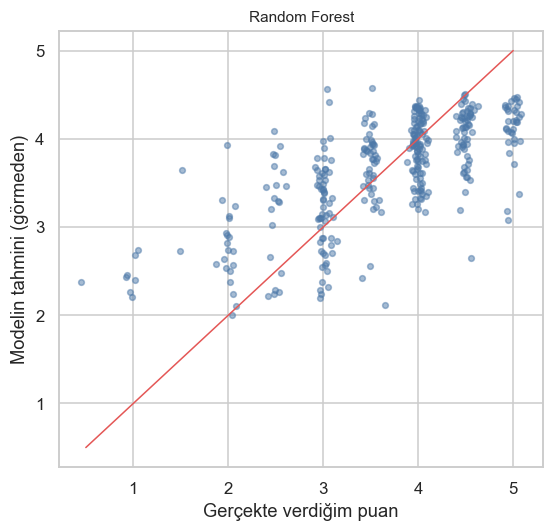

In [7]:
best_name = tab.loc[~tab['model'].isin([BASE])].iloc[0]['model']
print('En düşük RMSE\'li model:', best_name)

oof = cross_val_predict(models[best_name], X, y, cv=KFold(5, shuffle=True, random_state=SEED))
print(f'Bu 5 bölmeyle: RMSE {np.sqrt(np.mean((oof - y) ** 2)):.3f}, '
      f'MAE {np.mean(np.abs(oof - y)):.3f}, Spearman {stats.spearmanr(oof, y)[0]:.3f}')
print(f'Tahminlerin yarım puan içinde kalma oranı: {(np.abs(oof - y) <= 0.5).mean():.0%}, '
      f'bir puan içinde: {(np.abs(oof - y) <= 1.0).mean():.0%}')

fig, ax = plt.subplots(figsize=(5.2, 5))
jit = np.random.default_rng(SEED).normal(0, 0.05, len(y))
ax.scatter(y + jit, oof, s=14, alpha=0.5, color='#4c78a8')
ax.plot([0.5, 5], [0.5, 5], color='#e45756', lw=1)
ax.set_xlabel('Gerçekte verdiğim puan')
ax.set_ylabel('Modelin tahmini (görmeden)')
ax.set_title(best_name, fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '07_tahmin_vs_gercek.png')
plt.show()

## 6. Hangi özellikler işe yarıyor?

Permütasyon önemi: bir özelliğin değerlerini test kümesinde karıştırınca hata ne kadar artıyor. Her katta modeli eğitim kümesiyle kurup test kümesinde ölçüyorum ve sonucu 5 katın ortalaması olarak veriyorum. Birbiriyle ilişkili özellikler (örneğin yıl ve türler) önemi paylaşabilir, o yüzden sıralamayı kaba bir rehber olarak okumak lazım.

tmdb_vote_average    0.280
year                 0.080
g_Science_Fiction    0.008
log_popularity       0.007
g_Adventure          0.006
log_votes            0.006
g_Action             0.005
is_english           0.005
g_Drama              0.002
g_Thriller           0.002
n_genres             0.001
g_Mystery            0.001
dtype: float64


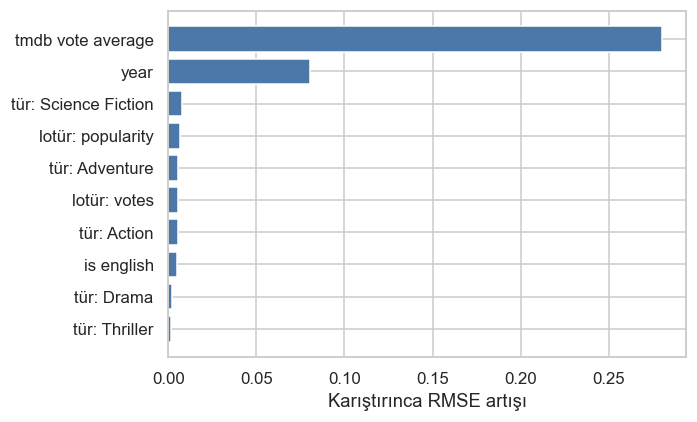

In [8]:
imps = []
for tr, te in KFold(5, shuffle=True, random_state=SEED).split(X):
    m = clone(models[best_name]).fit(X.iloc[tr], y[tr])
    pi = permutation_importance(m, X.iloc[te], y[te], scoring='neg_root_mean_squared_error',
                                n_repeats=20, random_state=SEED)
    imps.append(pi.importances_mean)
imp = pd.Series(np.mean(imps, axis=0), index=X.columns).sort_values(ascending=False)
print(imp.head(12).round(3))

top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(top.index.str.replace('g_', 'tür: ').str.replace('_', ' '), top.values, color='#4c78a8')
ax.set_xlabel('Karıştırınca RMSE artışı')
fig.tight_layout()
fig.savefig(FIG / '08_ozellik_onemi.png')
plt.show()

## 7. Sevdim mi, sevmedim mi?

Aynı soruyu sınıflandırma olarak da soruyorum: 4 ve üstü verdiğim filmleri ("sevdim") ayırt edebiliyor muyum? Ölçüt ROC AUC. 0,5 yazı tura demek, 1 mükemmel demek.

In [9]:
from xgboost import XGBClassifier
yc = df['loved'].values
print(f'Sevdim oranı: {yc.mean():.0%}')
cv_c = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
clfs = {
    'Temel çizgi': DummyClassifier(strategy='prior'),
    'Lojistik regresyon (L2)': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                             LogisticRegression(C=0.3, max_iter=2000)),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=2, subsample=0.7,
                             colsample_bytree=0.7, min_child_weight=3, random_state=SEED, n_jobs=1),
}
for name, m in clfs.items():
    s = cross_validate(m, X, yc, cv=cv_c, scoring=['roc_auc', 'accuracy', 'balanced_accuracy'])
    print(f'{name:26s} AUC {s["test_roc_auc"].mean():.3f} (±{s["test_roc_auc"].std():.3f})  '
          f'doğruluk {s["test_accuracy"].mean():.3f}  dengeli doğruluk {s["test_balanced_accuracy"].mean():.3f}')

Sevdim oranı: 55%


Temel çizgi                AUC 0.500 (±0.000)  doğruluk 0.555  dengeli doğruluk 0.500


Lojistik regresyon (L2)    AUC 0.829 (±0.047)  doğruluk 0.760  dengeli doğruluk 0.755


XGBoost                    AUC 0.843 (±0.046)  doğruluk 0.757  dengeli doğruluk 0.751


## 8. İzleme listemi sıralamak

En düşük RMSE'li modeli tüm 355 filmle eğitip, izleme listemdeki ve henüz puanlamadığım filmlere uyguluyorum. Hata payı yaklaşık yukarıdaki RMSE kadar, o yüzden tek bir filmin tahminini değil sıralamanın genel yönünü ciddiye alıyorum.

In [10]:
films = pd.read_csv(ROOT / 'data' / 'processed' / 'films_enriched.csv')
wl = pd.read_csv(ROOT / 'data' / 'raw' / 'watchlist.csv')
rated = set(df['uri'])
cand = films[films['uri'].isin(wl['Letterboxd URI']) & ~films['uri'].isin(rated)].copy()
print('İzleme listesinde:', len(wl), '| TMDB verisi olan ve puanlamadığım:', len(cand))

final = clone(models[best_name]).fit(X, y)
cand['tahmin'] = np.clip(final.predict(build(cand)), 0.5, 5).round(2)
cand = cand.sort_values('tahmin', ascending=False)
out = cand[['name', 'year', 'tahmin', 'genres', 'directors', 'tmdb_vote_average']]
out.to_csv(ROOT / 'reports' / 'izleme_listesi_tahminleri.csv', index=False, encoding='utf-8-sig')

print('\nEn yüksek tahmin edilen 15:')
print(out.head(15).to_string(index=False))
print('\nEn düşük tahmin edilen 5:')
print(out.tail(5).to_string(index=False))

İzleme listesinde: 249 | TMDB verisi olan ve puanlamadığım: 247



En yüksek tahmin edilen 15:
              name  year  tahmin                        genres            directors  tmdb_vote_average
           Persona  1966    4.64                         Drama       Ingmar Bergman              8.100
  The Seventh Seal  1957    4.60                 Fantasy|Drama       Ingmar Bergman              8.135
          Harakiri  1962    4.60          Action|Drama|History     Masaki Kobayashi              8.470
 Wild Strawberries  1957    4.60                         Drama       Ingmar Bergman              8.073
          Close-Up  1990    4.59                   Crime|Drama     Abbas Kiarostami              7.985
           Le Trou  1960    4.59          Drama|Thriller|Crime       Jacques Becker              8.226
     Autumn Sonata  1978    4.59                         Drama       Ingmar Bergman              7.971
Children of Heaven  1997    4.56                  Drama|Family         Majid Majidi              7.869
      Come and See  1985    4.55      Drama|

## 9. Klasik 80/20 ayrımı

Şimdiye kadarki tüm sonuçlar çapraz doğrulamadan geliyor. Burada bir de klasik yolu deniyorum: filmlerin %20'sini en başta ayırıyorum ve model seçimi bitene kadar ona hiç bakmıyorum.

1. Filmleri %80 eğitim (284 film) ve %20 test (71 film) olarak ayırıyorum. Puan dağılımı iki kümede aynı kalsın diye ayrımı puan basamaklarına göre tabakalı yapıyorum.
2. Model ve ayar seçimini **sadece eğitim kümesinde**, 5 katlı ve 3 tekrarlı çapraz doğrulamayla yapıyorum.
3. Kazanan modeli tüm eğitim kümesiyle eğitip test kümesinde **bir kez** ölçüyorum.

71 film küçük bir test kümesi, o yüzden test RMSE'sinin bootstrap güven aralığını da veriyorum.

In [11]:
from sklearn.model_selection import train_test_split

strata = pd.cut(y, [0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0], include_lowest=True)   # 2,5 ve altı tek basamak
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, random_state=SEED, stratify=strata)
Xtr, Xte, ytr, yte = X.iloc[idx_tr], X.iloc[idx_te], y[idx_tr], y[idx_te]

print(f'Eğitim: {len(ytr)} film, ortalama {ytr.mean():.2f} | Test: {len(yte)} film, ortalama {yte.mean():.2f}')
dist = pd.DataFrame({'eğitim': pd.Series(ytr).value_counts(normalize=True),
                     'test': pd.Series(yte).value_counts(normalize=True)}).sort_index().fillna(0)
print((dist * 100).round(1).T.to_string())
print('İki kümenin puan dağılımı farklı mı? Mann-Whitney p =', round(stats.mannwhitneyu(ytr, yte).pvalue, 3))

Eğitim: 284 film, ortalama 3.66 | Test: 71 film, ortalama 3.68
        0.5  1.0  1.5  2.0  2.5   3.0   3.5   4.0   4.5  5.0
eğitim  0.4  2.5  0.7  4.6  6.0  16.9  13.4  29.2  16.5  9.9
test    0.0  0.0  0.0  9.9  4.2  16.9  14.1  28.2  16.9  9.9
İki kümenin puan dağılımı farklı mı? Mann-Whitney p = 0.996


### Model seçimi (sadece eğitim kümesi)

In [12]:
cv_tr = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
sel = {}
for name, (est, grid) in cands.items():
    gs = GridSearchCV(clone(est), grid, cv=cv_tr, scoring='neg_root_mean_squared_error', n_jobs=1)
    gs.fit(Xtr, ytr)                     # GridSearchCV en iyi ayarla tüm eğitim kümesinde yeniden eğitiyor
    sel[name] = gs
    print(f'{name:24s} eğitim içi CV RMSE {-gs.best_score_:.3f}  ayar: {gs.best_params_ or "sabit"}')

winner = min(sel, key=lambda k: -sel[k].best_score_)
print(f'\nSeçilen model: {winner}')

Film yılı + TMDB puanı   eğitim içi CV RMSE 0.687  ayar: sabit


Ridge (tüm özellikler)   eğitim içi CV RMSE 0.697  ayar: sabit


Spline + Ridge           eğitim içi CV RMSE 0.691  ayar: {'columntransformer__spl__n_knots': 4}


Sıralı lojistik          eğitim içi CV RMSE 0.657  ayar: sabit


Random Forest            eğitim içi CV RMSE 0.650  ayar: {'randomforestregressor__max_features': 0.66, 'randomforestregressor__min_samples_leaf': 3}


Gradient Boosting        eğitim içi CV RMSE 0.663  ayar: {'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__n_estimators': 150}


XGBoost                  eğitim içi CV RMSE 0.662  ayar: {'xgbregressor__max_depth': 3, 'xgbregressor__n_estimators': 200}


LightGBM                 eğitim içi CV RMSE 0.664  ayar: {'lgbmregressor__n_estimators': 200, 'lgbmregressor__num_leaves': 4}

Seçilen model: Random Forest


### Test kümesinde tek ölçüm

Seçilen modeli; eğitim ortalamasını tahmin eden temel çizgi ve iki değişkenli basit modelle karşılaştırıyorum. Farkların aralığını aynı test filmlerini yeniden örnekleyerek (eşleşmiş bootstrap) hesaplıyorum.

In [13]:
def scores(pred, yt):
    return {'RMSE': np.sqrt(np.mean((pred - yt) ** 2)), 'MAE': np.mean(np.abs(pred - yt)),
            'R2': 1 - np.sum((yt - pred) ** 2) / np.sum((yt - yt.mean()) ** 2),
            'Spearman': stats.spearmanr(pred, yt)[0] if np.ptp(pred) > 0 else np.nan}

preds = {
    f'{winner} (seçilen)': sel[winner].predict(Xte),
    'Film yılı + TMDB puanı': sel['Film yılı + TMDB puanı'].predict(Xte),
    'Temel çizgi (eğitim ortalaması)': np.full(len(yte), ytr.mean()),
}
print(pd.DataFrame({k: scores(p, yte) for k, p in preds.items()}).T.round(3).to_string())

# eşleşmiş bootstrap: aynı test filmlerini yeniden örnekle
B = 5000
boot_idx = np.random.default_rng(SEED).integers(0, len(yte), size=(B, len(yte)))
def rmse_b(p):
    e = (p[boot_idx] - yte[boot_idx]) ** 2
    return np.sqrt(e.mean(axis=1))
p_win = preds[f'{winner} (seçilen)']
r_win = rmse_b(p_win)
r_base = rmse_b(preds['Temel çizgi (eğitim ortalaması)'])
r_simple = rmse_b(preds['Film yılı + TMDB puanı'])
q = lambda a: np.quantile(a, [0.025, 0.975]).round(3)
print(f'\nSeçilen modelin test RMSE %95 aralığı: {q(r_win)}')
print(f'Temel çizgi eksi seçilen model:  ortalama {np.mean(r_base - r_win):.3f}, %95 aralık {q(r_base - r_win)}')
print(f'Basit model eksi seçilen model:  ortalama {np.mean(r_simple - r_win):.3f}, %95 aralık {q(r_simple - r_win)}')

print(f'\nTahminlerin yarım puan içinde kalma oranı: {(np.abs(p_win - yte) <= 0.5).mean():.0%}, '
      f'bir puan içinde: {(np.abs(p_win - yte) <= 1.0).mean():.0%}')

                                  RMSE    MAE     R2  Spearman
Random Forest (seçilen)          0.666  0.520  0.396     0.609
Film yılı + TMDB puanı           0.683  0.540  0.365     0.597
Temel çizgi (eğitim ortalaması)  0.857  0.717 -0.001       NaN

Seçilen modelin test RMSE %95 aralığı: [0.541 0.79 ]
Temel çizgi eksi seçilen model:  ortalama 0.193, %95 aralık [0.058 0.33 ]
Basit model eksi seçilen model:  ortalama 0.018, %95 aralık [-0.031  0.067]

Tahminlerin yarım puan içinde kalma oranı: 56%, bir puan içinde: 90%


### Aşırı öğrenme kontrolü

Aynı modelin eğitim kümesindeki hatası, eğitim içi çapraz doğrulama hatası ve test hatası yan yana. Eğitim hatası diğer ikisinden çok düşükse model eğitim verisini ezberliyor demektir. Bunu her aday için gösteriyorum. Buradaki test sütunu seçimde kullanılmadı, sadece şeffaflık için.

                 model  eğitim (ezber)  eğitim içi CV  test
         Random Forest           0.382          0.650 0.666
       Sıralı lojistik           0.644          0.657 0.666
               XGBoost           0.411          0.662 0.678
     Gradient Boosting           0.412          0.663 0.664
              LightGBM           0.506          0.664 0.665
Film yılı + TMDB puanı           0.675          0.687 0.683
        Spline + Ridge           0.584          0.691 0.693
Ridge (tüm özellikler)           0.623          0.697 0.664


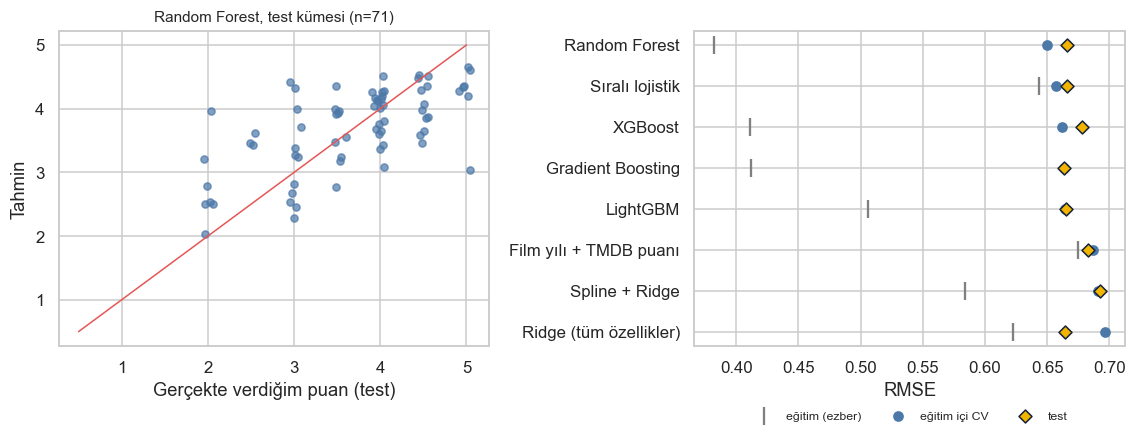

In [14]:
rows = []
for name, gs in sel.items():
    rows.append({'model': name,
                 'eğitim (ezber)': np.sqrt(np.mean((gs.predict(Xtr) - ytr) ** 2)),
                 'eğitim içi CV': -gs.best_score_,
                 'test': np.sqrt(np.mean((gs.predict(Xte) - yte) ** 2))})
of = pd.DataFrame(rows).sort_values('eğitim içi CV').reset_index(drop=True)
print(of.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax = axes[0]
jit = np.random.default_rng(SEED).normal(0, 0.05, len(yte))
ax.scatter(yte + jit, p_win, s=22, alpha=0.7, color='#4c78a8')
ax.plot([0.5, 5], [0.5, 5], color='#e45756', lw=1)
ax.set_xlabel('Gerçekte verdiğim puan (test)')
ax.set_ylabel('Tahmin')
ax.set_title(f'{winner}, test kümesi (n={len(yte)})', fontsize=10)
ax = axes[1]
pos = np.arange(len(of))
ax.scatter(of['eğitim (ezber)'], pos, marker='|', s=140, color='gray', label='eğitim (ezber)')
ax.scatter(of['eğitim içi CV'], pos, marker='o', color='#4c78a8', label='eğitim içi CV')
ax.scatter(of['test'], pos, marker='D', color='#f2b400', edgecolor='#14233a', label='test')
ax.set_yticks(pos)
ax.set_yticklabels(of['model'])
ax.invert_yaxis()
ax.set_xlabel('RMSE')
ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(FIG / '09_tutma_testi.png')
plt.show()

## 10. Ne çıktı?

Bölüm 9 dışındaki sonuçlar 355 filmin 5 katlı, 10 tekrarlı çapraz doğrulamasından geliyor. Hata ölçüsü RMSE, puan ölçeğinin kendi biriminde okunuyor.

**Tahmin yapabiliyorum.** Herkese ortalamamı tahmin eden temel çizgi 0,91 RMSE veriyor. Sadece TMDB puanını kullanan doğrusal model bunu 0,70'e, film yılını eklemek 0,68'e indiriyor. Tüm modeller temel çizgiden anlamlı derecede iyi (düzeltilmiş p < 0,001).

**Model sıralaması.** En düşük RMSE'yi Random Forest (0,649) verdi. Onu sıralı lojistik regresyon (0,656), LightGBM (0,662), Gradient Boosting (0,664) ve XGBoost (0,665) izliyor. Bu beşi arasındaki farklar standart sapmaların (yaklaşık 0,055) çok altında, yani pratikte aynı yerdeler. Spline eklemek basit modele bir şey katmadı (0,685), yani yıl ve TMDB puanının etkisi aşağı yukarı doğrusal.

**Basit modeli geçebiliyor muyuz?** "Film yılı + TMDB puanı" modeline göre Random Forest 0,033, sıralı lojistik 0,026 RMSE daha iyi. Tek tek bakınca bu farklar sınırda anlamlı (düzeltilmiş p = 0,040 ve 0,020), ama dokuz model karşılaştırdığım için Holm düzeltmesi yapınca ikisi de anlamlılığını kaybediyor (0,32 ve 0,18). XGBoost ve LightGBM için düzeltmesiz p bile 0,3 civarında. Dürüst özet: ek özellikler ve esnek modeller küçük bir iyileşme sağlıyor gibi görünüyor, ama bu örneklemle bunu kanıtlayamıyorum.

**İç içe çapraz doğrulama.** Model ve ayar seçimini her dış bölmenin içinde yapınca RMSE 0,662 (±0,097) çıkıyor. Aynı bölmelerde basit model 0,678, temel çizgi 0,908. İç skorlar dış skorlardan ortalama 0,016 daha iyimser. Yani "en iyi modeli seç ve raporla" yaklaşımı 0,649 diyor, seçimi de hesaba katan dürüst tahmin 0,66 civarı. Dış bölmelerin 5'inde Random Forest, 2'sinde XGBoost, 2'sinde sıralı lojistik ve 1'inde Gradient Boosting kazandı. Kazananın bölmeden bölmeye değişmesi, bu modellerin gerçekten birbirine yakın olduğunu gösteriyor.

**Klasik 80/20 ayrımı da aynı şeyi söylüyor.** 284 filmlik eğitim kümesinde yaptığım seçim yine Random Forest'ı çıkardı (eğitim içi CV RMSE 0,650). En baştan ayırdığım ve o ana kadar hiç bakmadığım 71 filmde test RMSE'si 0,666 (bootstrap %95 aralığı 0,54 ile 0,79), MAE 0,52, R² 0,40. Tahminlerin %56'sı yarım puan, %90'ı bir puan içinde. Aynı test filmlerinde temel çizgi 0,857 verdi, fark 0,19 ve aralığı sıfırı içermiyor (0,06 ile 0,33). Basit modele göre fark ise 0,018 ve aralığı sıfırı içeriyor (-0,03 ile 0,07). Yani tek bir tutma testinde de model temel çizgiyi açıkça geçiyor ama basit modelden ayrışamıyor. Test hatası (0,666) çapraz doğrulama tahminlerine (0,65 ile 0,66) çok yakın, bu da çapraz doğrulama sonuçlarının iyimser olmadığını gösteriyor.

**Aşırı öğrenme.** Random Forest eğitim kümesinde 0,38 hata yapıyor, yani eğitim filmlerini büyük ölçüde ezberliyor. Ama eğitim içi CV (0,65) ve test hatası (0,67) birbirine yakın, bu yüzden ezber genelleme tahminimizi bozmuyor. Ağaç modellerinde bu beklenen bir durum. Sıralı lojistik regresyonda bu fark neredeyse yok (eğitim 0,64, CV 0,66, test 0,67), dört parametreli bir model ezberleyecek kadar esnek değil.

**Sıralı model en ilginç sonuç.** Yalnızca dört özellikle (film yılı, TMDB puanı, log oy sayısı, İngilizce) Random Forest'a çok yaklaşıyor ve katsayıları yorumlanabiliyor:
- TMDB puanında 1 standart sapmalık artış (0,69 puan) daha yüksek bir puan basamağında olma olasılığımı (odds) 5,1 katına çıkarıyor (%95 aralık 3,8 ile 7,0).
- Film 1 standart sapma (yaklaşık 15 yıl) daha yeni olunca odds 0,64'e düşüyor (0,51 ile 0,81).
- TMDB puanı sabitken oy sayısı 1 standart sapma artınca odds 0,64'e düşüyor (0,47 ile 0,87). Yani aynı TMDB puanındaki iki filmden daha az bilinenini daha çok seviyorum.
- İngilizce olmak bu değişkenler sabitken anlamlı değil (p = 0,23). EDA'da gördüğüm yabancı dil farkı büyük ölçüde bu filmlerin daha eski ve TMDB'de daha yüksek puanlı olmasından geliyor gibi.

**Özellik önemi.** Random Forest için permütasyon önemi aynı hikâyeyi anlatıyor: TMDB puanı (0,28) ve film yılı (0,08) baskın, türlerin her biri 0,01'in altında.

**Hata payı.** Random Forest görmediği bir filmde ortalama 0,5 puan yanılıyor. Tahminlerin %58'i gerçek puanımın yarım puan içinde, %89'u bir puan içinde. Tahmin ile gerçek puan arasındaki Spearman korelasyonu 0,68, yani filmleri sıralamada tek tek puanlardan daha iyi.

**Sevdim mi, sevmedim mi?** 4 ve üstünü ayırmada lojistik regresyon AUC 0,83, XGBoost 0,84 aldı (temel çizgi 0,50). Doğruluk ikisinde de %76 civarı. Aradaki fark standart sapmanın (0,046) çok altında.

**İzleme listesi.** 247 filmi Random Forest ile sıraladım. En üstte Bergman, Kobayashi, Kiarostami, Tarkovski ve Kieślowski gibi eski ve TMDB'de yüksek puanlı filmler var (Persona, The Seventh Seal, Harakiri, Wild Strawberries). En altta yeni aksiyon, bilim kurgu ve korku filmleri duruyor (Salvation, Megalopolis, Longlegs). Liste `reports/izleme_listesi_tahminleri.csv` dosyasında.

### Sınırlar

- 355 film az. Modeller arasındaki farklar gürültü seviyesinde, sıralamayı kesin okumamak lazım.
- Model "benim zevkim" ile "TMDB'nin ortalaması ve filmin yaşı"nı ayıramıyor. Kalabalığın sevmediği ama benim sevdiğim filmler tahminde hep yanlış kalacak.
- Yönetmen, oyuncu ve anahtar kelime bilgilerini kullanmadım. 355 filmde yönetmenlerin çoğu bir kez geçiyor. Bunları metin vektörlerine çevirmek bir sonraki adım olabilir.
- İzleme listesindeki filmlerin çoğu tanınmış filmler. TMDB puanı düşük ya da az bilinen filmlerde tahmin daha az güvenilir.
